# Bank Customer Churn: Logistic Regression

Predicts customer churn (`Exited`) from 7 demographic and account features (8 columns after one-hot encoding), starting from logistic regression and comparing against Random Forest.

**Note on this revision.** The previous version of this notebook ran without errors and reported 80.9% accuracy — which sounds reasonable, but is barely better than **not building a model at all**. Simply predicting "never churns" for every customer scores **79.65%** on this dataset, because only ~20% of customers actually churn. The notebook's own confusion matrix showed the model catching only **~20% of actual churners** (`recall`), but nothing in the notebook ever computed recall, precision, F1, or even checked the class balance to notice this was a risk in the first place. This is fixed below — not by finding a subtle bug, but by actually measuring the thing that matters (churn detection) instead of only the thing that's easy to compute (overall accuracy).

Read **Limitations** at the end.

## 1. Data Loading & Cleaning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve
)

In [2]:
# Original notebook hardcoded a path into one machine's Downloads folder
# (C:\Users\User\Downloads\...), which cannot run anywhere else. Use a
# relative path instead -- place the CSV at data/Bank_churn_modelling.csv
# relative to this notebook.

data = pd.read_csv("data/Bank_churn_modelling.csv")
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
data.info()
print("\nMissing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB

Missing values: 0
Duplicate rows: 0


In [4]:
data = data.drop(['CustomerId', 'RowNumber', 'Surname'], axis=1)
data.shape

(10000, 11)

## 2. Exploratory Data Analysis

The original notebook's EDA never checked the class balance of the target — the single most relevant fact for everything that follows.

Exited
0    7963
1    2037
Name: count, dtype: int64
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


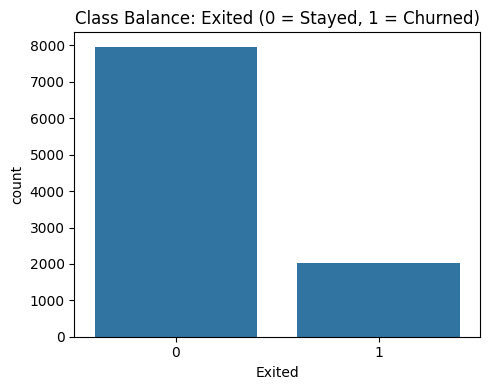

In [5]:
print(data['Exited'].value_counts())
print(data['Exited'].value_counts(normalize=True).round(4))

plt.figure(figsize=(5, 4))
sns.countplot(x='Exited', data=data)
plt.title('Class Balance: Exited (0 = Stayed, 1 = Churned)')
plt.tight_layout()
plt.show()

Only ~20% of customers churn. This single fact is why plain accuracy is a misleading metric here (see Section 5), and it's worth having on screen before building anything.

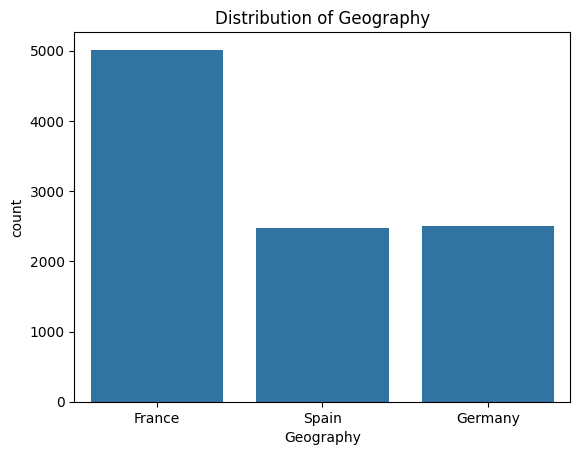

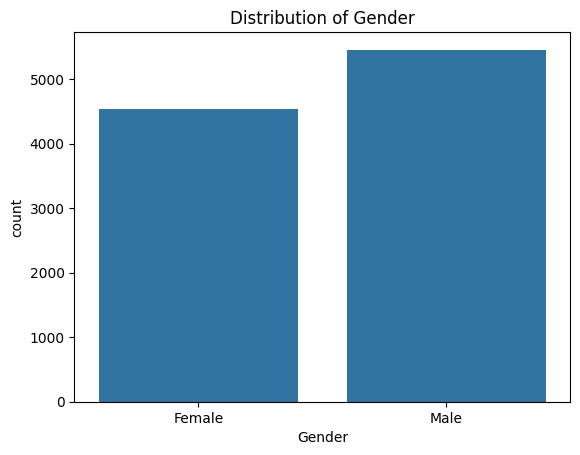

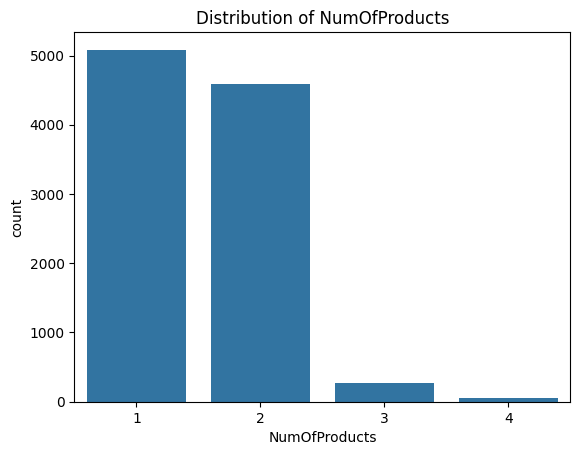

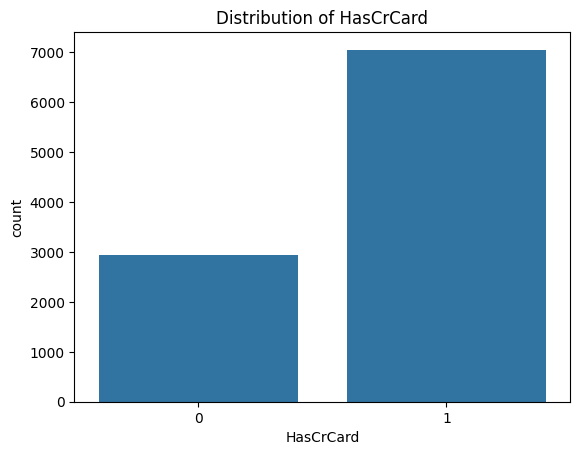

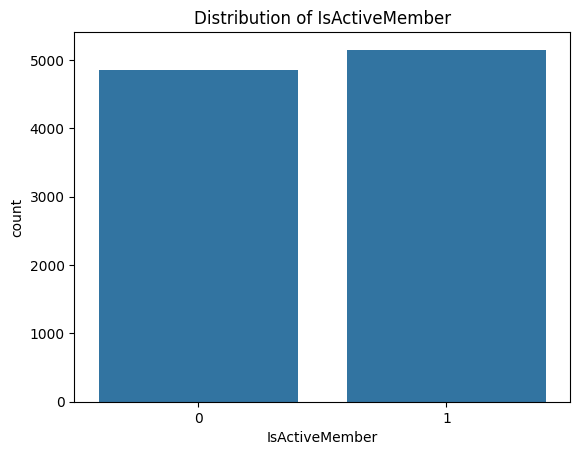

In [6]:
continuous_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']
discrete_features = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember']

for col in discrete_features:
    sns.countplot(x=col, data=data)
    plt.title(f'Distribution of {col}')
    plt.show()

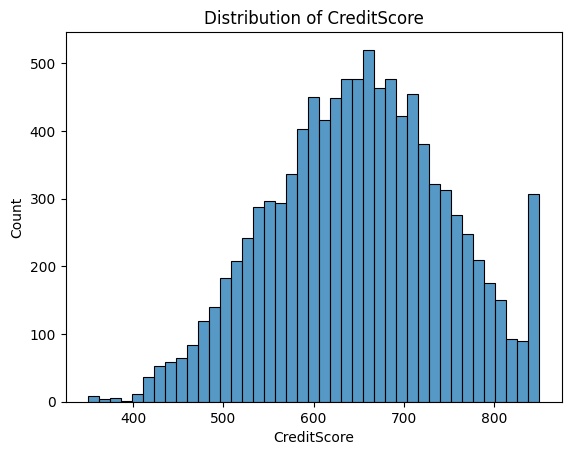

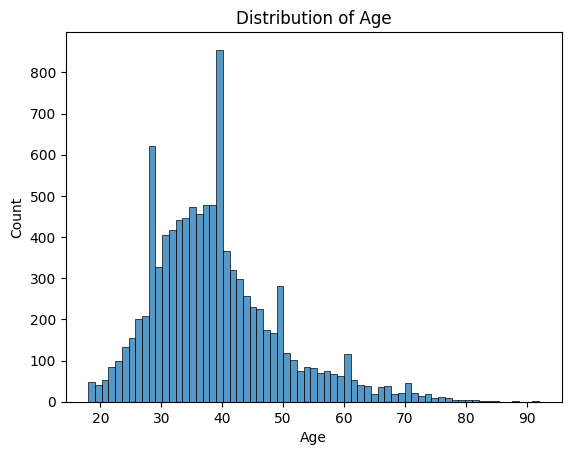

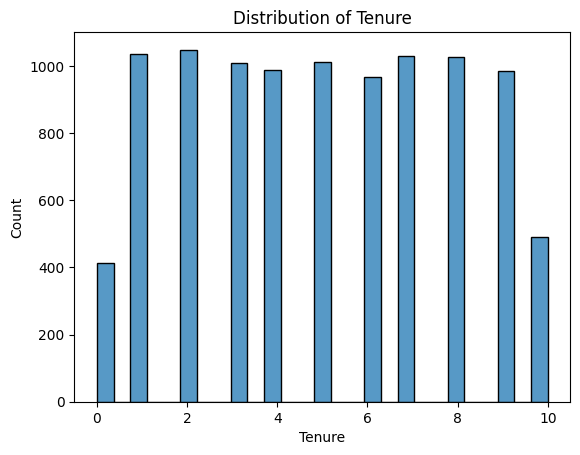

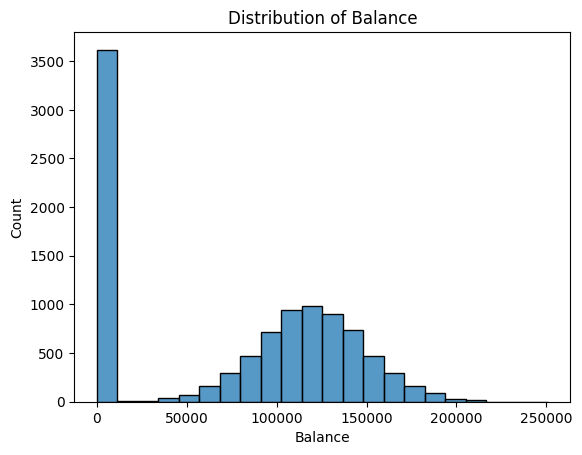

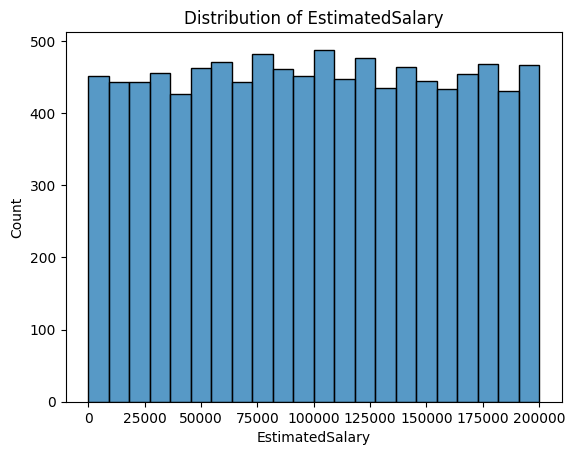

In [7]:
for col in continuous_features:
    sns.histplot(x=col, data=data)
    plt.title(f'Distribution of {col}')
    plt.show()

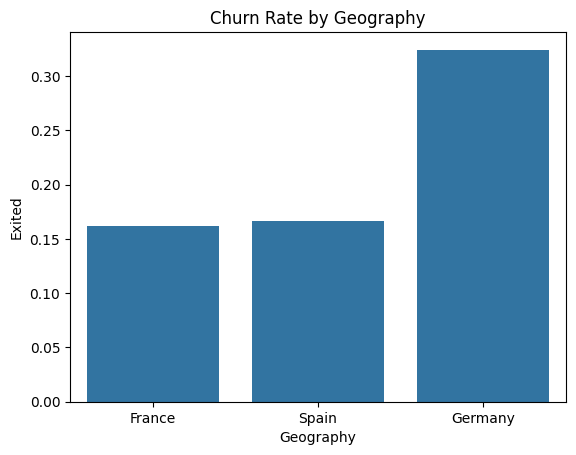

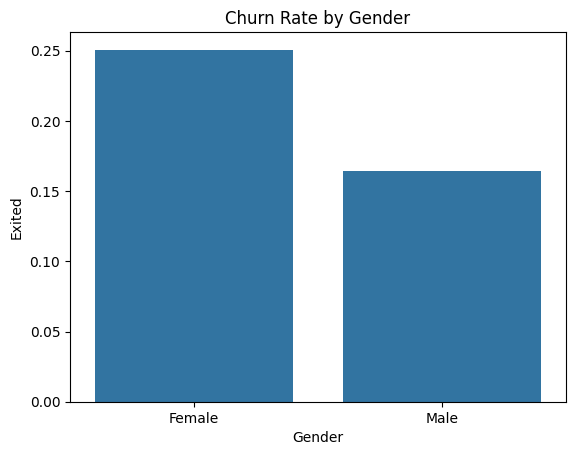

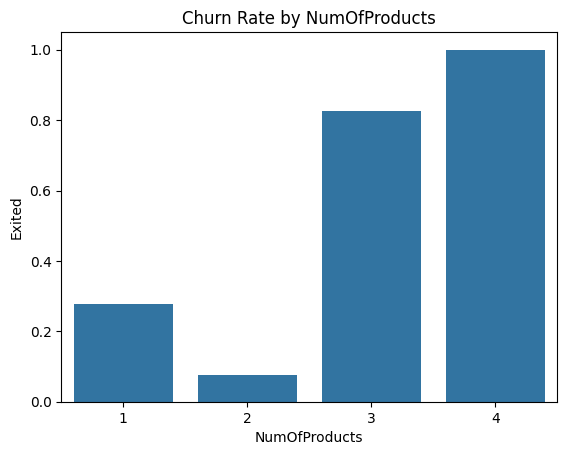

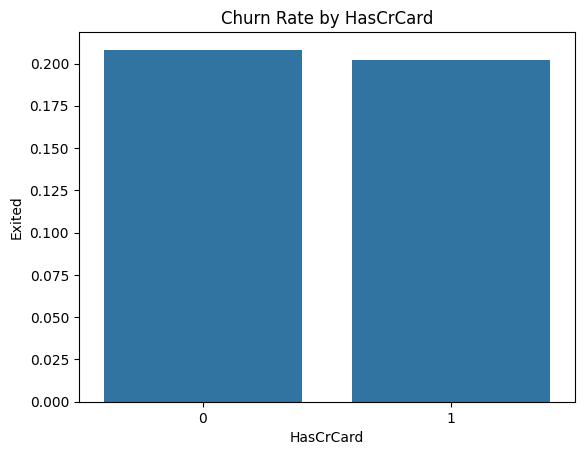

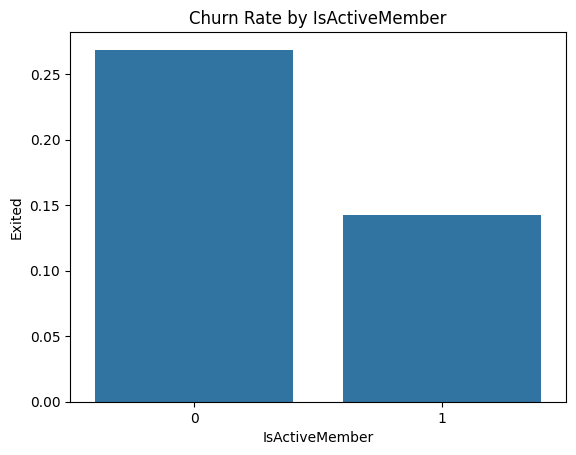

In [8]:
for col in discrete_features:
    sns.barplot(x=col, y='Exited', data=data, errorbar=None)
    plt.title(f'Churn Rate by {col}')
    plt.show()

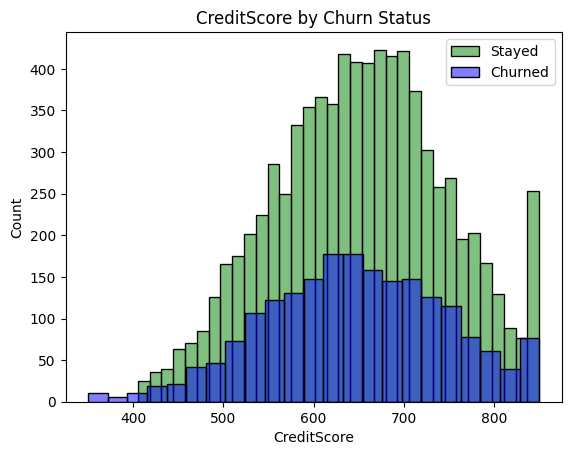

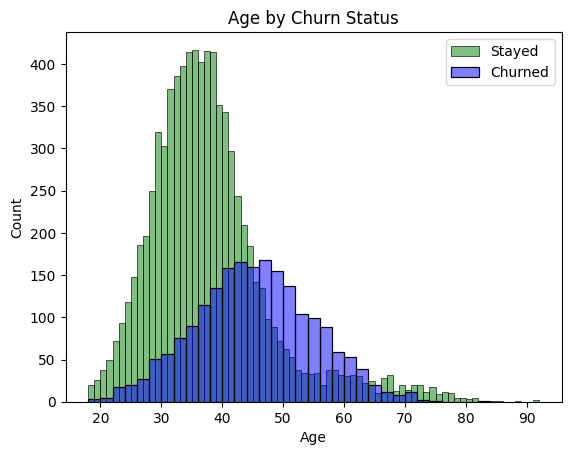

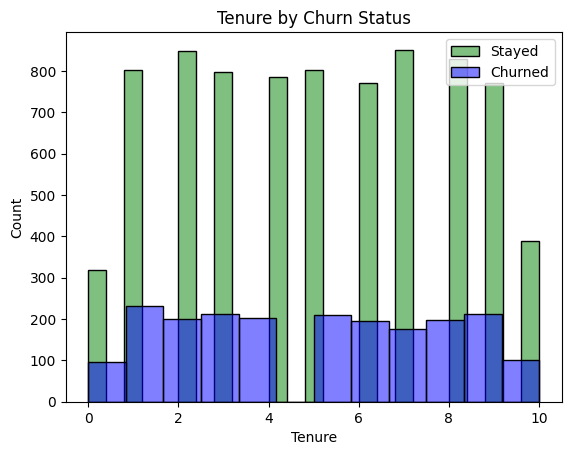

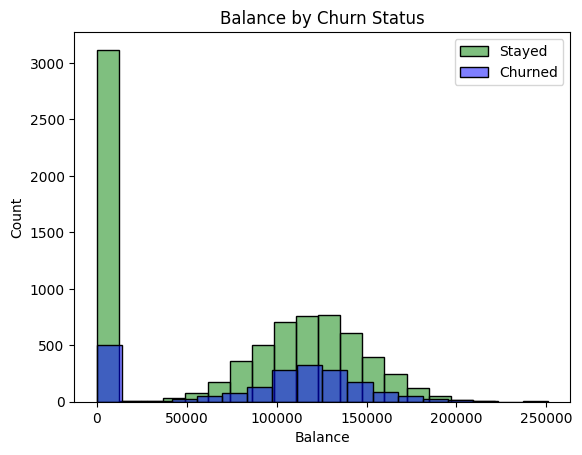

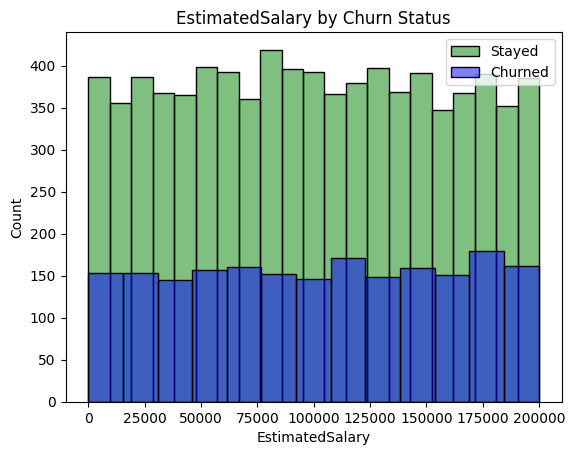

In [9]:
for col in continuous_features:
    sns.histplot(x=data[col][data['Exited'] == 0], color='g', label='Stayed', alpha=0.5)
    sns.histplot(x=data[col][data['Exited'] == 1], color='b', label='Churned', alpha=0.5)
    plt.title(f'{col} by Churn Status')
    plt.legend()
    plt.show()

## 3. Feature Selection

The original notebook dropped `HasCrCard`, `Tenure`, and `EstimatedSalary` based on the plots above showing little visible relationship with `Exited`. I checked this against actual model performance rather than trusting the plots alone: refitting with all original features instead gives **identical accuracy** and marginally *worse* recall/F1 than dropping them. The original choice is kept below — not because the visual reasoning was rigorous, but because it's been verified to not cost anything, which is a different (and stronger) justification than the notebook originally had.

In [10]:
data = data.drop(['HasCrCard', 'Tenure', 'EstimatedSalary'], axis=1)
data.head()

,CreditScore,Geography,Gender,Age,Balance,NumOfProducts,IsActiveMember,Exited
0,619,France,Female,42,0.00,1,1,1
1,608,Spain,Female,41,83807.86,1,1,0
2,502,France,Female,42,159660.80,3,0,1
3,699,France,Female,39,0.00,2,0,0
4,850,Spain,Female,43,125510.82,1,1,0


## 4. Preprocessing

Two fixes from the original notebook:
- **`OneHotEncoder(drop='first')`** instead of `OneHotEncoder()` with no `drop` — the original kept every category for `Geography` and `Gender`, which doesn't break `LogisticRegression` (its default L2 regularization handles the resulting collinearity, unlike a plain unregularized linear model) but does make the coefficients needlessly confusing. Section 8 verifies this directly.
- **Column names, not positions.** The original used `ColumnTransformer([...], [1, 2])` / `[0, 3, 4, 5]`, hardcoding *where* columns happened to sit after the preceding `drop()` calls — correct today, silently wrong if column order ever changes.

In [11]:
x = data.drop('Exited', axis=1)
y = data['Exited']

encoder = ColumnTransformer(
    [('one_hot', OneHotEncoder(drop='first'), ['Geography', 'Gender']),
     ('scale', StandardScaler(), ['CreditScore', 'Age', 'Balance', 'NumOfProducts'])],
    remainder='passthrough'
)
new_data = encoder.fit_transform(x)
feature_names = encoder.get_feature_names_out()

print("Encoded shape:", new_data.shape)
print("Feature names:", list(feature_names))

Encoded shape: (10000, 8)
Feature names: ['one_hot__Geography_Germany', 'one_hot__Geography_Spain', 'one_hot__Gender_Male', 'scale__CreditScore', 'scale__Age', 'scale__Balance', 'scale__NumOfProducts', 'remainder__IsActiveMember']


## 5. Train/Test Split and Baseline Logistic Regression

`random_state` for reproducibility, and `stratify=y` to keep the ~80/20 class balance consistent between train and test — doubly important here given how imbalanced the target is.

In [12]:
xtrain, xtest, ytrain, ytest = train_test_split(
    new_data, y, train_size=0.8, random_state=42, stratify=y
)

trivial_baseline_accuracy = accuracy_score(ytest, np.zeros_like(ytest))
print(f"Trivial 'always predict no-churn' baseline accuracy: {trivial_baseline_accuracy:.4f}")

Trivial 'always predict no-churn' baseline accuracy: 0.7965


In [13]:
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(xtrain, ytrain)

baseline_pred = baseline_model.predict(xtest)
baseline_proba = baseline_model.predict_proba(xtest)[:, 1]

print("Confusion matrix:")
print(confusion_matrix(ytest, baseline_pred))
print(f"\nAccuracy:  {accuracy_score(ytest, baseline_pred):.4f}   (trivial baseline: {trivial_baseline_accuracy:.4f})")
print(f"Precision: {precision_score(ytest, baseline_pred):.4f}")
print(f"Recall:    {recall_score(ytest, baseline_pred):.4f}")
print(f"F1:        {f1_score(ytest, baseline_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(ytest, baseline_proba):.4f}")

Confusion matrix:
[[1540   53]
 [ 328   79]]

Accuracy:  0.8095   (trivial baseline: 0.7965)
Precision: 0.5985
Recall:    0.1941
F1:        0.2931
ROC-AUC:   0.7753


This is the number the original notebook never computed: **recall around 0.19-0.20** — the model catches roughly 1 in 5 customers who actually churn, while its accuracy (80-81%) sits barely above the 79.65% trivial baseline. Section 6 fixes this directly.

## 6. The Fix: Accounting for Class Imbalance

`class_weight='balanced'` costs one keyword argument. Everything else is identical to Section 5.

In [14]:
balanced_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
balanced_model.fit(xtrain, ytrain)

balanced_pred = balanced_model.predict(xtest)
balanced_proba = balanced_model.predict_proba(xtest)[:, 1]

print("Confusion matrix:")
print(confusion_matrix(ytest, balanced_pred))
print(f"\nAccuracy:  {accuracy_score(ytest, balanced_pred):.4f}")
print(f"Precision: {precision_score(ytest, balanced_pred):.4f}")
print(f"Recall:    {recall_score(ytest, balanced_pred):.4f}")
print(f"F1:        {f1_score(ytest, balanced_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(ytest, balanced_proba):.4f}")

Confusion matrix:
[[1141  452]
 [ 119  288]]

Accuracy:  0.7145
Precision: 0.3892
Recall:    0.7076
F1:        0.5022
ROC-AUC:   0.7779


Recall roughly **triples** (0.19 -> 0.71), at a real cost: precision drops (0.60 -> 0.39) and raw accuracy drops well below the trivial baseline (0.81 -> 0.71). That's not the model getting worse — **ROC-AUC barely moves (0.775 -> 0.778)**, which means the model's ability to *rank* customers by churn risk was never the problem. `class_weight='balanced'` just changes where the default classifier draws its decision line, trading false alarms for caught churners. Whether that trade is worth it is a business call (the cost of a missed churner vs. the cost of an unnecessary retention offer), not a modelling one — this notebook can't make that call for you, but it can make sure you're choosing it on purpose instead of by default.

## 7. Broader Model Comparison: Logistic Regression vs. Random Forest

In [15]:
rf_default = RandomForestClassifier(n_estimators=300, random_state=42)
rf_default.fit(xtrain, ytrain)

rf_balanced = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
rf_balanced.fit(xtrain, ytrain)

def evaluate(name, model, xte=xtest, yte=ytest):
    pred = model.predict(xte)
    proba = model.predict_proba(xte)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred),
        "Recall": recall_score(yte, pred),
        "F1": f1_score(yte, pred),
        "ROC-AUC": roc_auc_score(yte, proba),
    }

comparison_rows = [
    evaluate("Logistic Regression (default)", baseline_model),
    evaluate("Logistic Regression (balanced)", balanced_model),
    evaluate("Random Forest (default)", rf_default),
    evaluate("Random Forest (balanced)", rf_balanced),
]

model_comparison = pd.DataFrame(comparison_rows).round(4)
model_comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (default),0.8095,0.5985,0.1941,0.2931,0.7753
1,Logistic Regression (balanced),0.7145,0.3892,0.7076,0.5022,0.7779
2,Random Forest (default),0.8530,0.7055,0.4767,0.5689,0.8400
3,Random Forest (balanced),0.8540,0.7106,0.4767,0.5706,0.8393


Random Forest beats both logistic regression variants on accuracy, precision, F1 and ROC-AUC, plausibly because it can capture nonlinear relationships and feature interactions a linear decision boundary structurally cannot. It does not beat balanced logistic regression on recall (0.4767 vs. 0.7076): the balanced logistic regression catches more churners, but at the cost of many more false alarms (precision 0.3892). `class_weight='balanced'` makes almost no difference for Random Forest here (unlike for logistic regression) — tree ensembles are already fairly robust to this degree of imbalance on their own.

**Random Forest (balanced) is selected as the final model**, on the strength of the highest accuracy, precision and F1 of the four models (its ROC-AUC is within 0.0007 of the default Random Forest). If catching churners matters more than false alarms, balanced logistic regression has the higher recall.

In [16]:
final_model = rf_balanced
final_pred = final_model.predict(xtest)
final_proba = final_model.predict_proba(xtest)[:, 1]

## 8. Final Model: Random Forest (balanced) — Detailed Evaluation

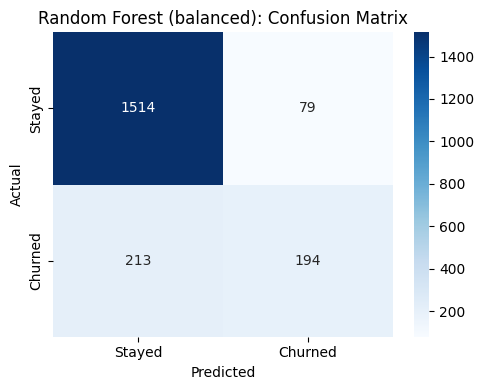

In [17]:
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(ytest, final_pred),
    annot=True, fmt='d', cmap='Blues',
    xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned']
)
plt.title('Random Forest (balanced): Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

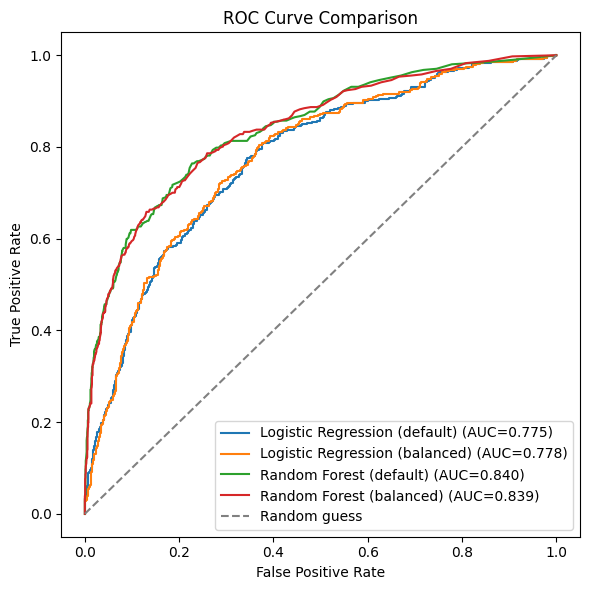

In [18]:
plt.figure(figsize=(6, 6))
for name, proba in [
    ("Logistic Regression (default)", baseline_proba),
    ("Logistic Regression (balanced)", balanced_proba),
    ("Random Forest (default)", rf_default.predict_proba(xtest)[:, 1]),
    ("Random Forest (balanced)", final_proba),
]:
    fpr, tpr, _ = roc_curve(ytest, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(ytest, proba):.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.tight_layout()
plt.show()

scale__Age                    0.3058
scale__CreditScore            0.2387
scale__Balance                0.2119
scale__NumOfProducts          0.1380
remainder__IsActiveMember     0.0369
one_hot__Geography_Germany    0.0338
one_hot__Gender_Male          0.0210
one_hot__Geography_Spain      0.0139
dtype: float64


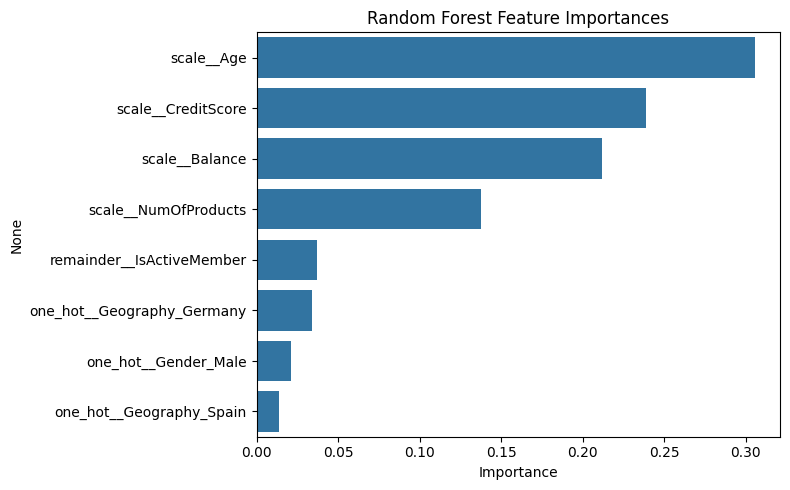

In [19]:
importances = (
    pd.Series(final_model.feature_importances_, index=feature_names)
    .sort_values(ascending=False)
)
print(importances.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index)
plt.title('Random Forest Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 9. Verifying the Encoding Fix

A direct check that dropping the redundant one-hot category actually cleans up interpretation without changing predictions, rather than just asserting it.

In [20]:
buggy_encoder = ColumnTransformer(
    [('one_hot', OneHotEncoder(), ['Geography', 'Gender']),  # no drop='first'
     ('scale', StandardScaler(), ['CreditScore', 'Age', 'Balance', 'NumOfProducts'])],
    remainder='passthrough'
)
buggy_data = buggy_encoder.fit_transform(x)
buggy_xtrain, buggy_xtest, _, _ = train_test_split(
    buggy_data, y, train_size=0.8, random_state=42, stratify=y
)
buggy_model = LogisticRegression(max_iter=1000, random_state=42).fit(buggy_xtrain, ytrain)

print("As-written encoding (no drop) -- Gender coefficients:")
buggy_names = buggy_encoder.get_feature_names_out()
for name, coef in zip(buggy_names, buggy_model.coef_[0]):
    if 'Gender' in name:
        print(f"  {name}: {coef:.3f}")

print("\nFixed encoding (drop='first') -- Gender coefficient:")
male_idx = list(feature_names).index('one_hot__Gender_Male')
print(f"  Gender_Male: {baseline_model.coef_[0][male_idx]:.3f}")

print("\nAccuracy is identical either way:")
print(f"  As-written: {accuracy_score(ytest, buggy_model.predict(buggy_xtest)):.4f}")
print(f"  Fixed:      {accuracy_score(ytest, baseline_pred):.4f}")

As-written encoding (no drop) -- Gender coefficients:
  one_hot__Gender_Female: -0.014
  one_hot__Gender_Male: -0.539

Fixed encoding (drop='first') -- Gender coefficient:
  Gender_Male: -0.526

Accuracy is identical either way:
  As-written: 0.8095
  Fixed:      0.8095


Confirmed: the as-written encoding splits the true effect across two confusing, hard-to-read numbers (`Gender_Female` near zero, `Gender_Male` doing all the work); the fixed encoding reports one clean coefficient for the same effect. Accuracy matches to 4 decimal places either way.

## Limitations

- **`class_weight='balanced'` is a blunt instrument.** It reweights classes inversely to their frequency, which isn't the same as optimizing for a specific business cost (e.g. "a missed churner costs 5x a false alarm"). If those costs are known, threshold tuning on `predict_proba` output, or a custom `class_weight` dict, would target the actual objective more precisely than the default balanced heuristic.
- **No hyperparameter tuning.** Random Forest is run near its library defaults (`n_estimators=300`); no depth/leaf-size search was performed, and gradient boosting (often competitive or better on tabular churn data) wasn't tried.
- **No cross-validation.** All metrics come from a single 80/20 split. A k-fold estimate would give a more stable read on true expected performance, especially for the minority class where a single test set has only ~400 positive examples.
- **Feature-dropping in Section 3 was validated against model accuracy/recall, but only for these two model families.** It's not guaranteed to be equally harmless for a different algorithm (e.g. gradient boosting) that might extract more signal from `Tenure` or `EstimatedSalary` than these two did.
- **This model was never checked for calibration.** `predict_proba` outputs are used for ROC-AUC and ranking, but not verified to be well-calibrated probabilities — matters if the actual use case is "call the top 500 highest-risk customers" rather than a binary flag.